In [1]:
import sys
import os
import random
import time
from pathlib import Path

import torch
import torchvision
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [3]:
from img_generation.datasets import Config, DatasetType, load_dataloaders, VAE_TRANSFORM_MONO
from img_generation.models.vae import VAE, train_vae, vae_loss_function
from img_generation.utils import EarlyStopping

In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [5]:
config = Config(dataset_type=DatasetType.FASHION_MNIST, data_dir="../data/fashion_mnist", model_type="vae", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config, transform=VAE_TRANSFORM_MONO)

print(f"All classes: {classes}")    # tiny-imagenet labels are of poor quality
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 54000 images, 10 classes.
All classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Number of all classes: 10


In [6]:
for x, y in dataloaders["train"]:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input img shape: torch.Size([128, 1, 28, 28])
class: tensor([8, 0, 4, 9, 0, 9, 7, 5, 6, 8, 2, 5, 0, 6, 1, 9, 1, 1, 6, 9, 1, 0, 9, 2,
        5, 5, 4, 0, 9, 5, 3, 5, 9, 2, 4, 5, 6, 9, 0, 8, 0, 6, 5, 6, 1, 3, 9, 0,
        6, 8, 8, 8, 0, 8, 5, 0, 5, 8, 8, 2, 7, 0, 9, 3, 5, 6, 4, 4, 5, 8, 2, 7,
        8, 2, 6, 8, 3, 2, 0, 0, 6, 2, 5, 4, 1, 1, 6, 3, 0, 1, 9, 6, 2, 3, 8, 1,
        1, 0, 0, 5, 2, 3, 6, 1, 5, 5, 9, 7, 6, 7, 3, 9, 8, 9, 9, 1, 3, 3, 5, 2,
        7, 2, 6, 1, 8, 1, 9, 4])


In [7]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

In [8]:
latent_dim = 64
hidden_dim = 32
y_embed_dim = 32


vae = VAE(input_channels=input_channels, hidden_dim_channels=hidden_dim, latent_dim=latent_dim, num_classes=len(classes), class_embed_dim=y_embed_dim).to(device=device)
optim = torch.optim.Adam(vae.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optim, gamma=0.99)
early_stopping = EarlyStopping(patience=10, delta = 0.1)

100%|██████████| 421/421 [00:08<00:00, 50.84it/s] 


(Epoch 1/[train]) -> Total Loss:	3821.451 -> Reconstruction Loss:	3166.215 -> lr: 0.001


100%|██████████| 47/47 [00:02<00:00, 22.20it/s]


(Epoch 1/[val]) -> Total Loss:	2972.463 -> Reconstruction Loss:	2326.498 -> lr: 0.001


100%|██████████| 421/421 [00:05<00:00, 72.22it/s] 


...

(Epoch 9/[val]) -> Total Loss:	2418.281 -> Reconstruction Loss:	1733.011 -> lr: 0.00092274469442792


100%|██████████| 421/421 [00:05<00:00, 75.18it/s] 


(Epoch 10/[train]) -> Total Loss:	2393.188 -> Reconstruction Loss:	1717.153 -> lr: 0.0009135172474836408


100%|██████████| 47/47 [00:02<00:00, 23.26it/s]

(Epoch 10/[val]) -> Total Loss:	2406.821 -> Reconstruction Loss:	1743.138 -> lr: 0.0009135172474836408


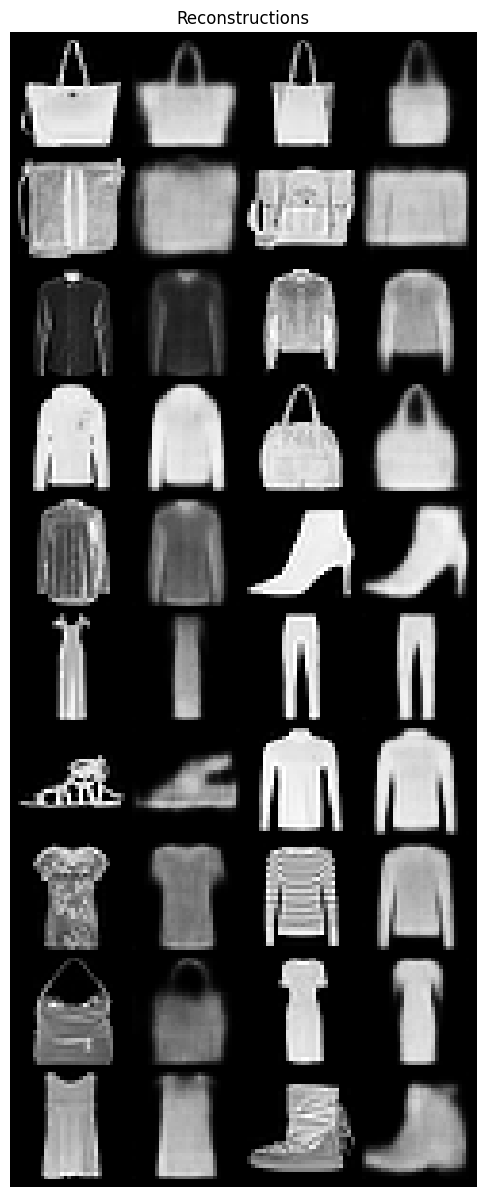

100%|██████████| 421/421 [00:05<00:00, 74.68it/s] 


(Epoch 11/[train]) -> Total Loss:	2379.152 -> Reconstruction Loss:	1701.555 -> lr: 0.0009043820750088043


100%|██████████| 47/47 [00:01<00:00, 23.80it/s]


(Epoch 11/[val]) -> Total Loss:	2392.625 -> Reconstruction Loss:	1722.517 -> lr: 0.0009043820750088043


100%|██████████| 421/421 [00:05<00:00, 74.70it/s] 


...

(Epoch 19/[val]) -> Total Loss:	2333.704 -> Reconstruction Loss:	1654.818 -> lr: 0.0008345137614500873


100%|██████████| 421/421 [00:05<00:00, 74.95it/s] 


(Epoch 20/[train]) -> Total Loss:	2303.540 -> Reconstruction Loss:	1622.743 -> lr: 0.0008261686238355864


100%|██████████| 47/47 [00:01<00:00, 23.79it/s]

(Epoch 20/[val]) -> Total Loss:	2317.183 -> Reconstruction Loss:	1631.836 -> lr: 0.0008261686238355864


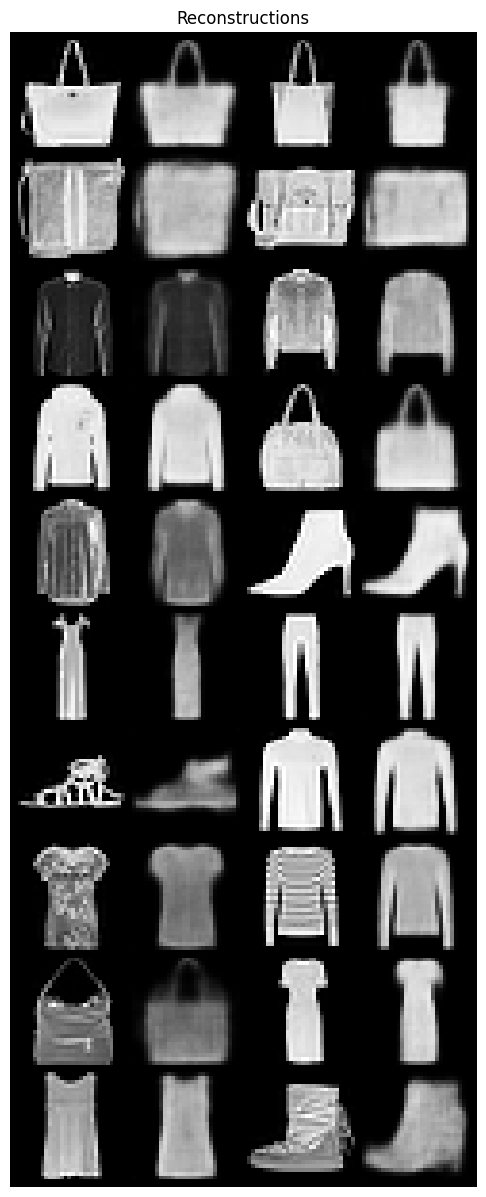

100%|██████████| 421/421 [00:05<00:00, 74.79it/s] 


(Epoch 21/[train]) -> Total Loss:	2298.167 -> Reconstruction Loss:	1615.248 -> lr: 0.0008179069375972306


100%|██████████| 47/47 [00:01<00:00, 23.59it/s]


(Epoch 21/[val]) -> Total Loss:	2323.315 -> Reconstruction Loss:	1638.682 -> lr: 0.0008179069375972306


100%|██████████| 421/421 [00:05<00:00, 75.18it/s] 


...

(Epoch 29/[val]) -> Total Loss:	2295.605 -> Reconstruction Loss:	1604.427 -> lr: 0.0007547192872036325


100%|██████████| 421/421 [00:05<00:00, 74.82it/s] 


(Epoch 30/[train]) -> Total Loss:	2260.732 -> Reconstruction Loss:	1578.533 -> lr: 0.0007471720943315961


100%|██████████| 47/47 [00:01<00:00, 23.71it/s]

(Epoch 30/[val]) -> Total Loss:	2279.989 -> Reconstruction Loss:	1595.019 -> lr: 0.0007471720943315961


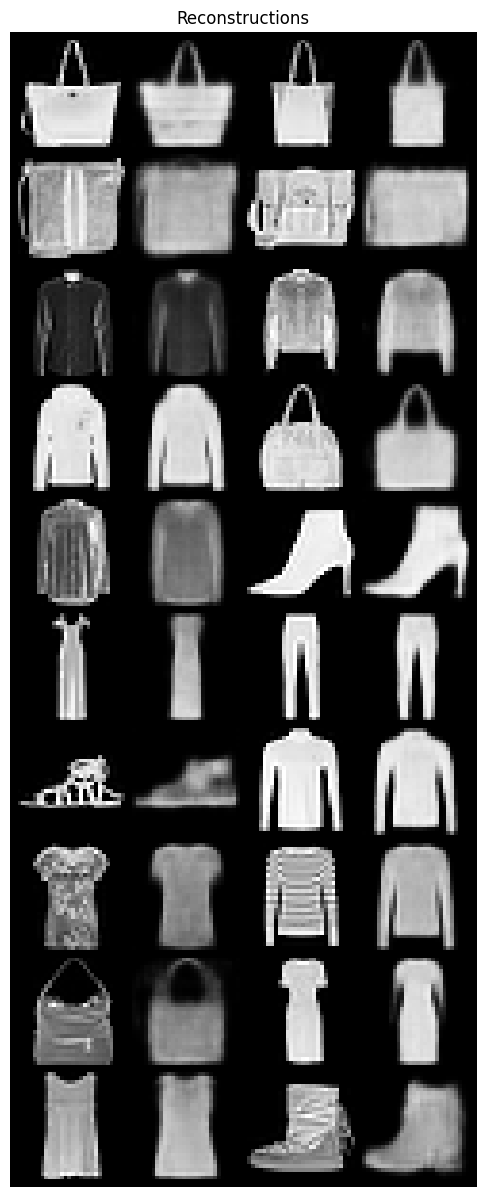

100%|██████████| 421/421 [00:05<00:00, 74.73it/s] 


(Epoch 31/[train]) -> Total Loss:	2260.835 -> Reconstruction Loss:	1575.372 -> lr: 0.0007397003733882801


100%|██████████| 47/47 [00:02<00:00, 23.13it/s]


(Epoch 31/[val]) -> Total Loss:	2286.481 -> Reconstruction Loss:	1594.072 -> lr: 0.0007397003733882801


100%|██████████| 421/421 [00:05<00:00, 75.04it/s] 


...

(Epoch 39/[val]) -> Total Loss:	2267.839 -> Reconstruction Loss:	1591.677 -> lr: 0.0006825545950103868


100%|██████████| 421/421 [00:05<00:00, 75.04it/s] 


(Epoch 40/[train]) -> Total Loss:	2233.273 -> Reconstruction Loss:	1551.055 -> lr: 0.000675729049060283


100%|██████████| 47/47 [00:02<00:00, 23.38it/s]

(Epoch 40/[val]) -> Total Loss:	2263.549 -> Reconstruction Loss:	1577.757 -> lr: 0.000675729049060283


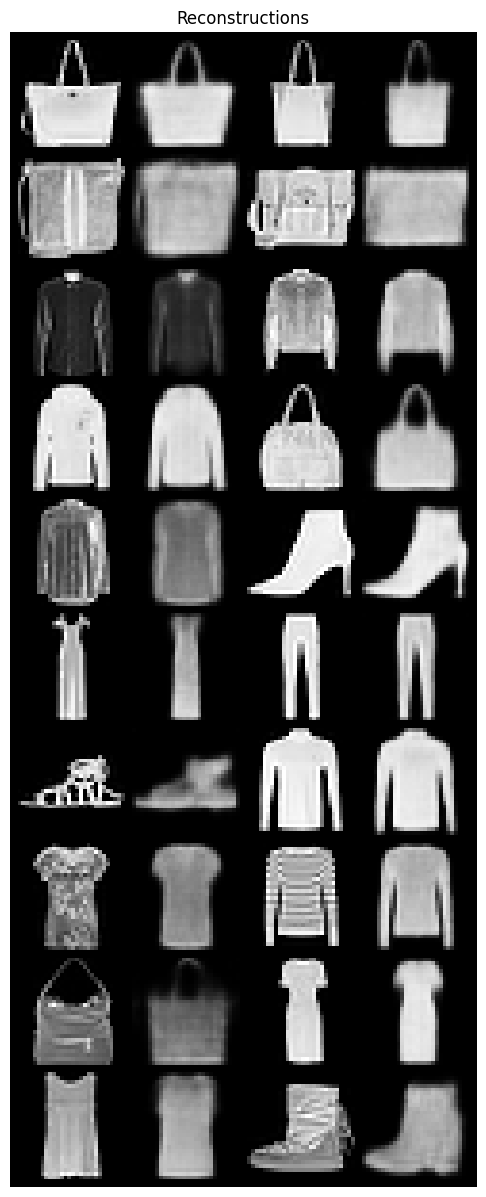

100%|██████████| 421/421 [00:05<00:00, 74.74it/s] 


(Epoch 41/[train]) -> Total Loss:	2231.262 -> Reconstruction Loss:	1548.989 -> lr: 0.0006689717585696801


100%|██████████| 47/47 [00:02<00:00, 22.91it/s]


(Epoch 41/[val]) -> Total Loss:	2262.469 -> Reconstruction Loss:	1591.543 -> lr: 0.0006689717585696801


100%|██████████| 421/421 [00:05<00:00, 73.34it/s] 


...

(Epoch 49/[val]) -> Total Loss:	2245.444 -> Reconstruction Loss:	1545.786 -> lr: 0.0006172901409422877


100%|██████████| 421/421 [00:05<00:00, 75.13it/s] 


(Epoch 50/[train]) -> Total Loss:	2212.853 -> Reconstruction Loss:	1530.226 -> lr: 0.0006111172395328649


100%|██████████| 47/47 [00:02<00:00, 23.28it/s]

(Epoch 50/[val]) -> Total Loss:	2246.991 -> Reconstruction Loss:	1563.878 -> lr: 0.0006111172395328649


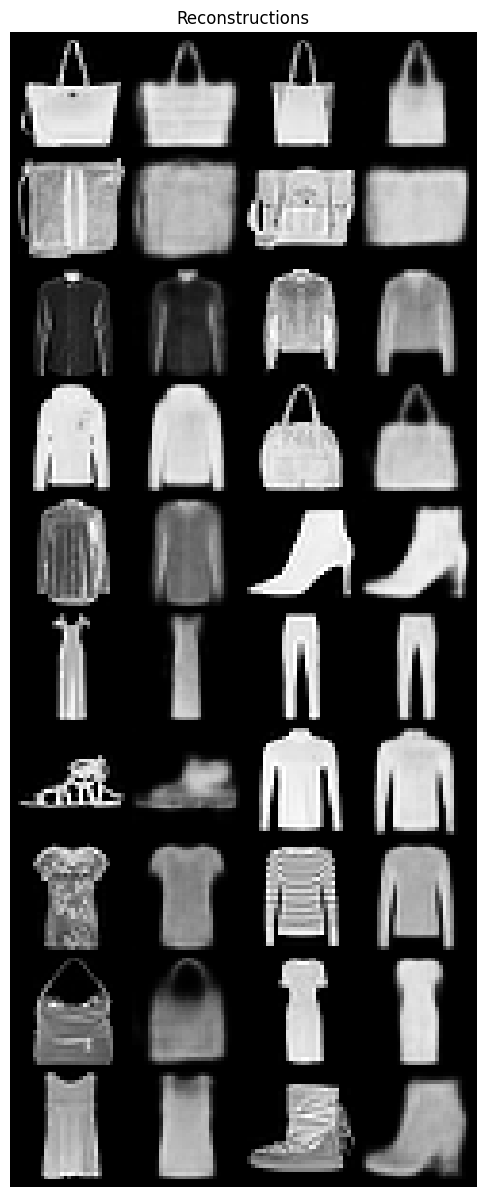

100%|██████████| 421/421 [00:05<00:00, 74.86it/s] 


(Epoch 51/[train]) -> Total Loss:	2211.365 -> Reconstruction Loss:	1530.066 -> lr: 0.0006050060671375363


100%|██████████| 47/47 [00:02<00:00, 23.38it/s]


(Epoch 51/[val]) -> Total Loss:	2240.330 -> Reconstruction Loss:	1556.020 -> lr: 0.0006050060671375363


100%|██████████| 421/421 [00:05<00:00, 74.59it/s] 


...

(Epoch 59/[val]) -> Total Loss:	2232.972 -> Reconstruction Loss:	1553.350 -> lr: 0.0005582661385478637


100%|██████████| 421/421 [00:05<00:00, 74.43it/s] 


(Epoch 60/[train]) -> Total Loss:	2198.912 -> Reconstruction Loss:	1518.108 -> lr: 0.000552683477162385


100%|██████████| 47/47 [00:02<00:00, 23.34it/s]

(Epoch 60/[val]) -> Total Loss:	2228.576 -> Reconstruction Loss:	1539.646 -> lr: 0.000552683477162385


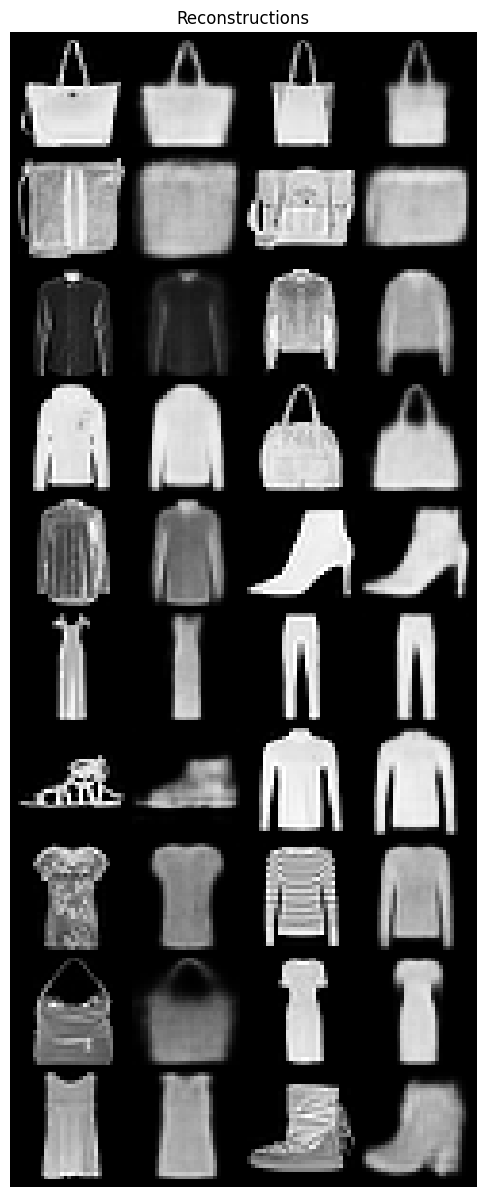

100%|██████████| 421/421 [00:05<00:00, 73.91it/s] 


(Epoch 61/[train]) -> Total Loss:	2197.672 -> Reconstruction Loss:	1515.684 -> lr: 0.0005471566423907612


100%|██████████| 47/47 [00:02<00:00, 22.97it/s]


(Epoch 61/[val]) -> Total Loss:	2233.720 -> Reconstruction Loss:	1556.291 -> lr: 0.0005471566423907612


100%|██████████| 421/421 [00:05<00:00, 74.07it/s] 


...

(Epoch 69/[val]) -> Total Loss:	2217.214 -> Reconstruction Loss:	1542.666 -> lr: 0.0005048858887870696


100%|██████████| 421/421 [00:05<00:00, 74.83it/s] 


(Epoch 70/[train]) -> Total Loss:	2185.928 -> Reconstruction Loss:	1505.127 -> lr: 0.0004998370298991989


100%|██████████| 47/47 [00:02<00:00, 23.34it/s]

(Epoch 70/[val]) -> Total Loss:	2225.447 -> Reconstruction Loss:	1545.575 -> lr: 0.0004998370298991989


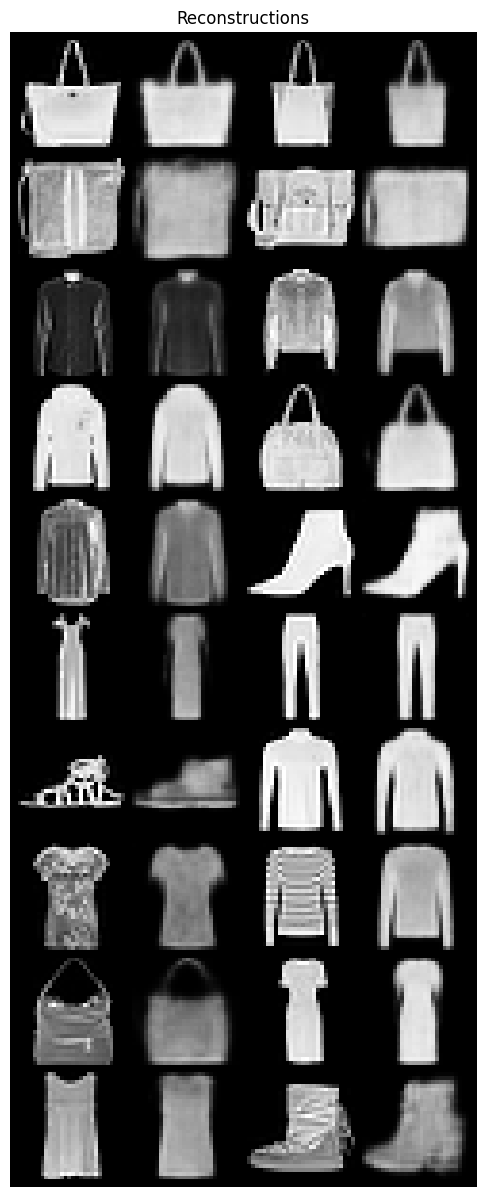

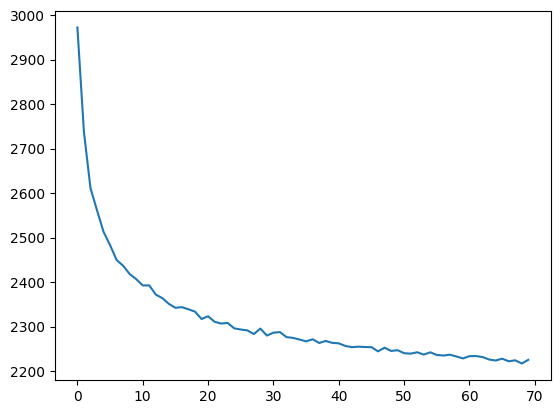

In [9]:
epochs = 70
warmup_epochs = 50
max_beta = 0.5
# max_beta = 1.0

start = time.time()
early_stopping, val_lossses = train_vae(model=vae, loaders=dataloaders, criterion=vae_loss_function, optimizer=optim, lr_scheduler=scheduler, 
                                early_stopping=early_stopping, num_epochs=epochs, warmup_epochs=warmup_epochs, loss_beta=max_beta, device=device)
end = time.time()
early_stopping.load_best_model(vae)

plt.plot(val_lossses)

In [11]:
model_path = "../pretrained_models/vae"

torch.save(vae.state_dict(), f=os.path.join(model_path, "cvae.pth"))

In [12]:
training_time = (end - start) / 60
print(f"Training lasted for {training_time} minutes")

Training lasted for 8.961609812577565 minutes


In [13]:
def visualize_reconstructions(model, input_imgs, labels, device):
    # Reconstruct images
    model.eval()
    with torch.no_grad():
        reconst_imgs, means, log_var = model(input_imgs.to(device), labels.to(device))
    reconst_imgs = reconst_imgs.cpu()
    
    # Plotting
    imgs = torch.stack([input_imgs, reconst_imgs], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=6, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [14]:
vae.eval()
with torch.inference_mode():    
    test_losses = []
    for x, y in tqdm(dataloaders["test"]):
        x = x.to(device)
        y = y.to(device)
        x_hat, mean, logvar = vae(x, y)
        total_loss, _ = vae_loss_function(x, x_hat, mean, logvar)
        test_losses.append(total_loss.item())
    print(f"Mean test loss: {np.mean(np.array(test_losses))}")

100%|██████████| 79/79 [00:03<00:00, 24.43it/s]

Mean test loss: 2192.7383500111255


torch.Size([27, 1, 28, 28])
torch.Size([27])


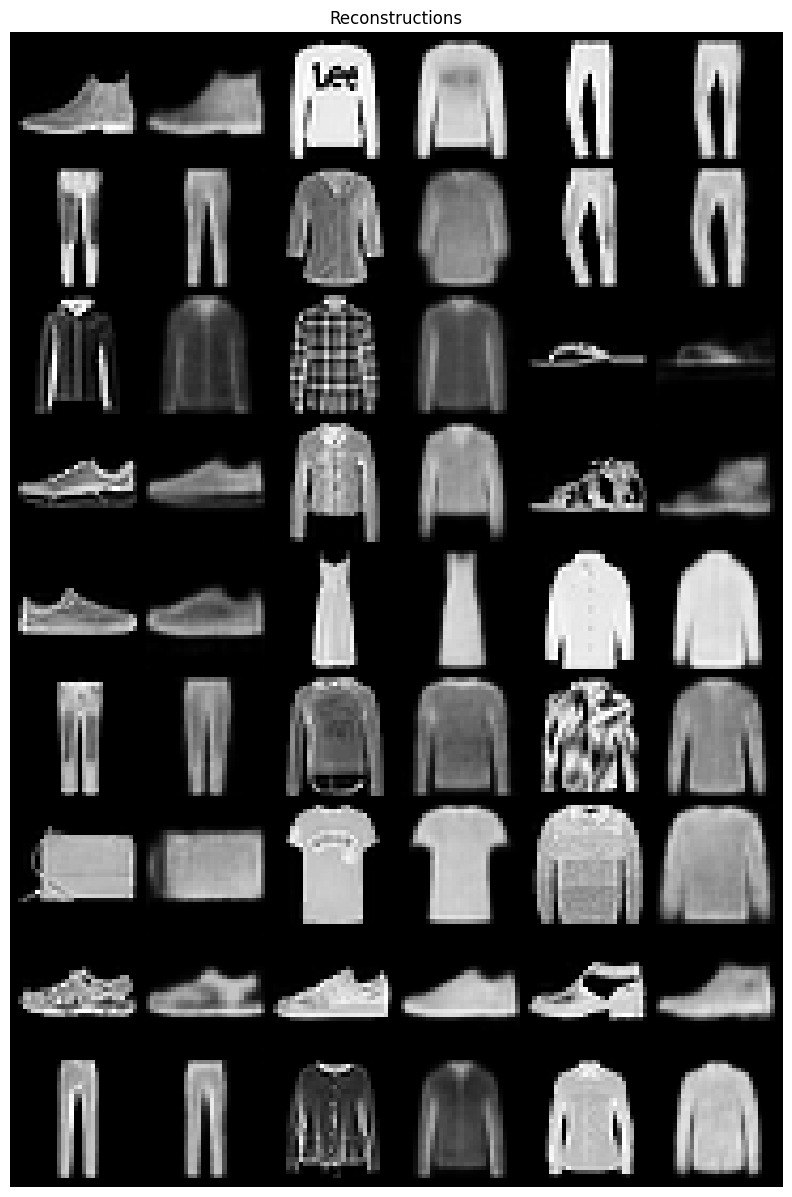

In [15]:
n_samples = 27
sample_imgs = torch.stack([dataloaders["test"].dataset[i][0] for i in range(n_samples)], dim=0)    # wraps all tensors in one one external tensor - [[..], [..], .., [..]]
sample_lables = torch.tensor([dataloaders["test"].dataset[i][1] for i in range(n_samples)])
print(sample_imgs.shape)
print(sample_lables.shape)
visualize_reconstructions(vae, input_imgs=sample_imgs, labels=sample_lables, device=device)

### Generations form noise

In [16]:
num_samples = 20

vae.eval()
with torch.no_grad():
    fixed_noise = torch.randn(num_samples, latent_dim, device=device)
    rnd_labels = torch.randint(0, len(classes), size=(num_samples,), device=device)
    generations_vae = vae.decoder(fixed_noise, rnd_labels)
    

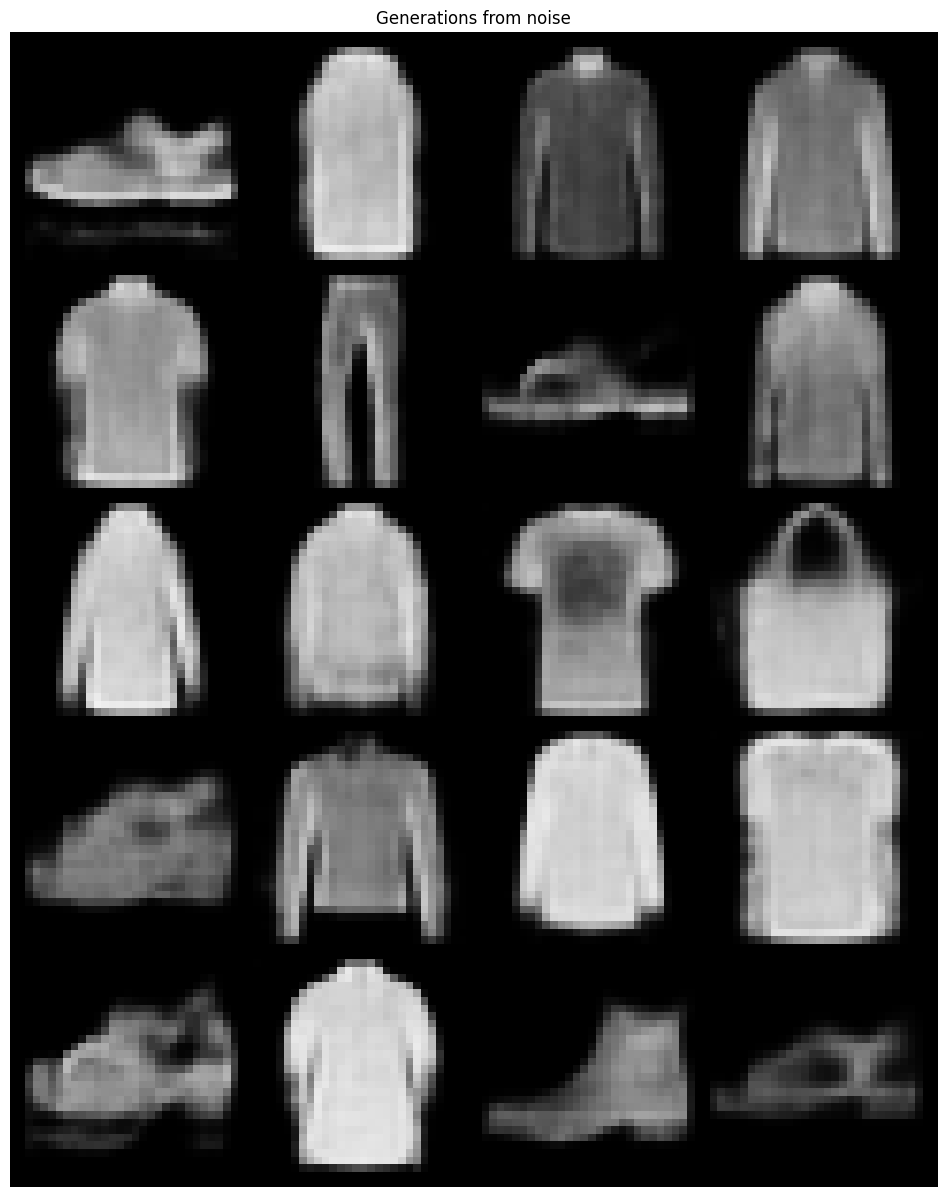

In [17]:
grid = torchvision.utils.make_grid(generations_vae.cpu()[:20], nrow=4, normalize=False) # produces 'channels first' format
grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
if len(generations_vae) == 4:
    plt.figure(figsize=(15,10))
else:
    plt.figure(figsize=(15,15))
plt.title("Generations from noise")
plt.imshow(grid)
plt.axis('off')
plt.show()